# Case 2: Five exams on the bank's file

**Applies** chapter 2 (Regularisation) and chapter 3 (Cross-validation), on the model case 1 left us:
the honest feature set, now in a logistic model.

**The question.** Case 1 trusted one validation slice of 8,238 customers. Would a different slice have
told a different story? And does the logistic model need a brake at all?

**By the end you can** run five-fold cross-validation with the scaler inside the folds, read the fold
spread, sweep the brake's strength `C`, and see L1 switch columns off.

**Search for:** k-fold cross validation scikit-learn, Pipeline data leakage, logistic regression C
regularization, L1 lasso feature selection.

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 11, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690"

def check(label, ok):
    """Print PASS or FAIL on one line, so a reader sees at a glance whether a step worked."""
    print(("PASS  " if ok else "FAIL  ") + label)

print("Charts and the check() helper are ready.")

Charts and the check() helper are ready.


In [2]:
# Load the day's public dataset once; later runs read the cached copy.
import io, zipfile, pathlib, urllib.request
import pandas as pd
CACHE = pathlib.Path.home() / ".cache" / "c2_datasets"
CACHE.mkdir(parents=True, exist_ok=True)

def fetch(url, name):
    path = CACHE / name
    if not path.exists():
        path.write_bytes(urllib.request.urlopen(url, timeout=60).read())
    return path

def load_bank():
    """UCI Bank Marketing, bank-additional-full.csv (CC BY 4.0). The zip holds a second zip."""
    f = CACHE / "bank-additional-full.csv"
    if not f.exists():
        outer = zipfile.ZipFile(fetch("https://archive.ics.uci.edu/static/public/222/bank+marketing.zip",
                                      "bank+marketing.zip"))
        inner = zipfile.ZipFile(io.BytesIO(outer.read("bank-additional.zip")))
        f.write_bytes(inner.read("bank-additional/bank-additional-full.csv"))
    return pd.read_csv(f, sep=";")

bank = load_bank()
print(f"{len(bank):,} calls, {bank.shape[1]} columns, {bank['y'].eq('yes').mean():.2%} said yes")

41,188 calls, 21 columns, 11.27% said yes


In [3]:
# The week's pipeline: the same columns, the same split and the same baseline every day.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, accuracy_score

PROFILE = ["age", "job", "marital", "education", "default", "housing", "loan"]
HISTORY = ["contact", "month", "day_of_week", "campaign", "previous", "poutcome"]
ECONOMY = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

def engineer(df):
    """Wednesday's fix for pdays: 999 means never contacted, so it becomes a flag plus the real days."""
    df = df.copy()
    df["never_contacted"] = (df["pdays"] == 999).astype(int)
    df["days_since_contact"] = np.where(df["pdays"] == 999, 0, df["pdays"])
    return df

# Wednesday's honest feature set: the customer table, the economy, the pdays flag. No duration.
HONEST = PROFILE + HISTORY + ECONOMY + ["never_contacted", "days_since_contact"]

def week_split(df, seed=42):
    """Test is sealed first (20 percent, the envelope); the rest splits 75/25 into train and validation."""
    y = (df["y"] == "yes").astype(int)
    rest, test = train_test_split(df.index, test_size=0.20, stratify=y, random_state=seed)
    train, val = train_test_split(rest, test_size=0.25, stratify=y.loc[rest], random_state=seed)
    return df.loc[train], df.loc[val], df.loc[test]

bank = engineer(bank)
train, val, test = week_split(bank)          # test stays in the sealed envelope until Friday
X_train, X_val = train[HONEST], val[HONEST]
y_train = (train["y"] == "yes").astype(int)
y_val = (val["y"] == "yes").astype(int)

# pandas 3 reads text as the "str" dtype, so test for numbers rather than for object.
NUM = [c for c in HONEST if pd.api.types.is_numeric_dtype(bank[c])]
CAT = [c for c in HONEST if c not in NUM]

def prep(scale=True):
    """One-hot the categories; scale the numbers for the linear model (trees do not need it)."""
    return ColumnTransformer([("num", StandardScaler() if scale else "passthrough", NUM),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])

print(f"train {len(train):,}  validation {len(val):,}  test {len(test):,} (sealed)")
print(f"{len(NUM)} number columns and {len(CAT)} category columns")

train 24,712  validation 8,238  test 8,238 (sealed)
10 number columns and 10 category columns


In [4]:
check("the honest set has 10 number and 10 category columns", (len(NUM), len(CAT)) == (10, 10))
check("duration stays out of the model", "duration" not in HONEST)

PASS  the honest set has 10 number and 10 category columns
PASS  duration stays out of the model


## Step 1: Predict, then re-deal the split five times

Same 32,950 customers outside the envelope, same model; only the seed that deals them into training
and validation changes. How far apart will the five validation AUCs land? Then guess whether a smaller
exam would swing more or less.

In [5]:
outside = pd.concat([train, val])                       # everything except the sealed test slice
y_out = (outside["y"] == "yes").astype(int)
logit = lambda C=1.0: Pipeline([("prep", prep()), ("model", LogisticRegression(C=C, max_iter=3000))])

seed_auc = []
for seed in [1, 2, 3, 4, 5]:
    a, b = train_test_split(outside.index, test_size=0.25, stratify=y_out, random_state=seed)
    m = logit().fit(outside.loc[a, HONEST], y_out.loc[a])
    seed_auc.append(roc_auc_score(y_out.loc[b], m.predict_proba(outside.loc[b, HONEST])[:, 1]))
print("validation AUC by seed:", [round(v, 3) for v in seed_auc])
print(f"lowest {min(seed_auc):.3f}, highest {max(seed_auc):.3f}, "
      f"a swing of {max(seed_auc) - min(seed_auc):.3f} from the deal alone")

validation AUC by seed: [0.79, 0.79, 0.789, 0.786, 0.788]
lowest 0.786, highest 0.790, a swing of 0.004 from the deal alone


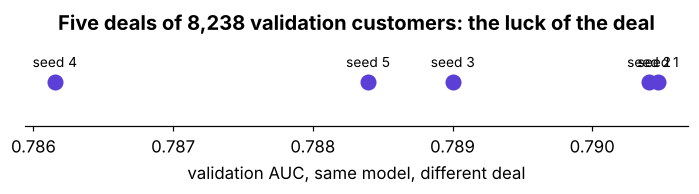

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 1.9))
ax.scatter(seed_auc, [0] * 5, s=90, color=VIOLET, zorder=3)
for s_, v in zip([1, 2, 3, 4, 5], seed_auc):
    ax.annotate(f"seed {s_}", (v, 0), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=9)
ax.set_yticks([]); ax.set_xlabel("validation AUC, same model, different deal")
ax.set_title("Five deals of 8,238 validation customers: the luck of the deal")
ax.spines["left"].set_visible(False); plt.tight_layout(); plt.show()

## Step 2: Five exams instead of one: cross-validation, done right

Cut the 24,712 training customers into five folds. Each fold takes one turn as the exam while the
other four teach. The scaler sits inside the `Pipeline`, so each turn learns its means and spreads
from the four teaching folds only.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
right_way = cross_val_score(logit(), X_train, y_train, cv=folds, scoring="roc_auc")
print("fold AUCs:", right_way.round(4))
print(f"mean {right_way.mean():.4f}, spread (standard deviation) {right_way.std():.4f}")
print(f"best fold minus worst fold: {right_way.max() - right_way.min():.3f}, on exams of about "
      f"{len(X_train) // 5:,} customers each")

fold AUCs: [0.7709 0.7687 0.7975 0.7969 0.7983]
mean 0.7865, spread (standard deviation) 0.0136
best fold minus worst fold: 0.030, on exams of about 4,942 customers each


Each fold's exam is smaller than the 8,238-customer validation slice, so its luck is larger: the folds
swing by about 0.03 where the five deals swung by 0.004. That spread is the size of the luck, and the
reason one fold, or one small split, is never the score.

## Step 3: The wrong way, and what it cost here

Scale all 24,712 rows first, then cross-validate: every exam fold has helped set the mean it is
scaled by. Predict the damage before you run it.

In [8]:
X_leaky = X_train.copy()
X_leaky[NUM] = StandardScaler().fit_transform(X_leaky[NUM])     # fitted on every fold at once
no_scaler = ColumnTransformer([("num", "passthrough", NUM),
                               ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
wrong_way = cross_val_score(Pipeline([("prep", no_scaler),
                                      ("model", LogisticRegression(max_iter=3000))]),
                            X_leaky, y_train, cv=folds, scoring="roc_auc")
print(f"scaler inside the folds  {right_way.mean():.5f}")
print(f"scaler before the folds  {wrong_way.mean():.5f}")
print(f"difference               {wrong_way.mean() - right_way.mean():+.5f}")

scaler inside the folds  0.78648
scaler before the folds  0.78645
difference               -0.00003


Tiny here, because a scaler learns only a mean and a spread per column, and 24,712 rows pin both down.
The habit still binds: the next step you put before the split (filling gaps with a mean, choosing
columns by their link to `y`, encoding a category by its yes rate) learns from the exam's answers,
and that leak can be large. Everything that learns goes inside the `Pipeline`.

**The rows run in time order.** The file is sorted from May 2008 to November 2010, and `shuffle=True`
deals customers from every year into every fold. Friday asks what happens when you train on the early
months and score the late ones; today, write the caveat beside every cross-validated number.

In [9]:
print("first rows:", bank[["month", "day_of_week"]].head(3).values.tolist())
print("last rows: ", bank[["month", "day_of_week"]].tail(3).values.tolist())
check("cross-validation ran five folds", len(right_way) == 5)
check("scaling before the folds moved the mean AUC by under 0.001 on this file",
      abs(wrong_way.mean() - right_way.mean()) < 0.001)

first rows: [['may', 'mon'], ['may', 'mon'], ['may', 'mon']]
last rows:  [['nov', 'fri'], ['nov', 'fri'], ['nov', 'fri']]
PASS  cross-validation ran five folds
PASS  scaling before the folds moved the mean AUC by under 0.001 on this file


## Step 4: Does the logistic model need a brake? Sweep C

In scikit-learn the brake's strength is written as `C`, and **a small C is a strong brake**
(C is 1 divided by the penalty). Predict where the cross-validated AUC peaks.

In [10]:
Cs = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]
sweep = []
for C_ in Cs:
    cv = cross_val_score(logit(C_), X_train, y_train, cv=folds, scoring="roc_auc")
    fit = logit(C_).fit(X_train, y_train)
    sweep.append({"C": C_, "train_auc": roc_auc_score(y_train, fit.predict_proba(X_train)[:, 1]),
                  "cv_auc": cv.mean(), "cv_spread": cv.std()})
sweep = pd.DataFrame(sweep)
print(sweep.round(4).to_string(index=False))

       C  train_auc  cv_auc  cv_spread
  0.0001     0.7628  0.7616     0.0122
  0.0010     0.7796  0.7763     0.0130
  0.0100     0.7880  0.7841     0.0121
  0.1000     0.7912  0.7864     0.0131
  1.0000     0.7916  0.7865     0.0136
 10.0000     0.7916  0.7864     0.0138
100.0000     0.7915  0.7864     0.0139


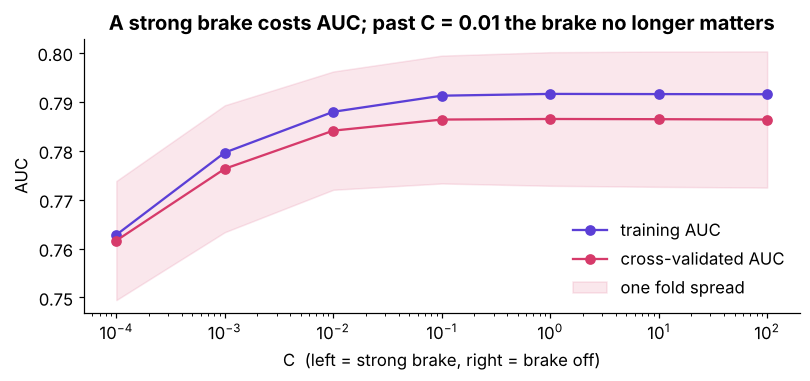

In [11]:
fig, ax = plt.subplots(figsize=(7.5, 3.6))
ax.plot(sweep["C"], sweep["train_auc"], "o-", color=VIOLET, label="training AUC")
ax.plot(sweep["C"], sweep["cv_auc"], "o-", color=ROSE, label="cross-validated AUC")
ax.fill_between(sweep["C"], sweep["cv_auc"] - sweep["cv_spread"], sweep["cv_auc"] + sweep["cv_spread"],
                color=ROSE, alpha=0.12, label="one fold spread")
ax.set_xscale("log"); ax.set_xlabel("C  (left = strong brake, right = brake off)")
ax.set_ylabel("AUC"); ax.legend(frameon=False, loc="lower right")
ax.set_title("A strong brake costs AUC; past C = 0.01 the brake no longer matters")
plt.tight_layout(); plt.show()

**Read it.** At C = 0.0001 the brake is so hard that the model underfits (bias). From C = 0.01 up, the
training and cross-validated curves sit together and flat: with 24,712 rows and 63 one-hot columns the
logistic model has little room to memorise, so there is little variance for a brake to remove. The
tree in case 1 had room for 3,662 leaves, which is why its brake mattered so much.

## Step 5: L1, the brake that switches columns off

An L1 penalty pushes weak coefficients to exactly zero. How many of the 63 columns survive?

In [12]:
l1_rows = []
for C_ in [0.001, 0.003, 0.01, 0.03, 0.1, 1]:
    m = Pipeline([("prep", prep()),
                  ("model", LogisticRegression(C=C_, l1_ratio=1, solver="liblinear"))]).fit(X_train, y_train)
    coef = m.named_steps["model"].coef_.ravel()
    l1_rows.append({"C": C_, "columns_kept": int((abs(coef) > 1e-8).sum()), "of": coef.size,
                    "val_auc": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
l1 = pd.DataFrame(l1_rows)
print(l1.round(4).to_string(index=False))

    C  columns_kept  of  val_auc
0.001             2  63   0.7455
0.003             4  63   0.7837
0.010             9  63   0.7892
0.030            20  63   0.7940
0.100            33  63   0.7963
1.000            45  63   0.7953


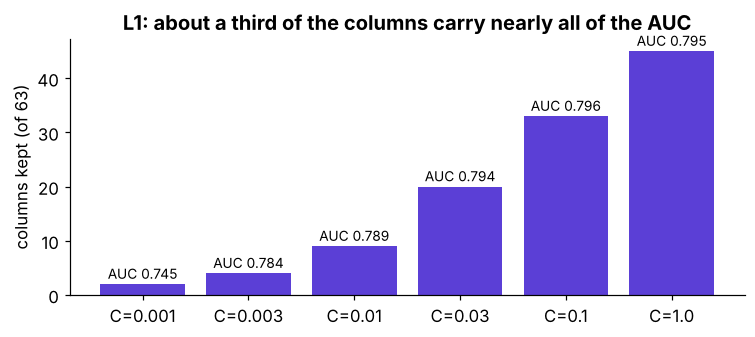

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(range(len(l1)), l1["columns_kept"], color=VIOLET)
for i, r in l1.iterrows():
    ax.text(i, r["columns_kept"] + 1, f"AUC {r['val_auc']:.3f}", ha="center", fontsize=9)
ax.set_xticks(range(len(l1))); ax.set_xticklabels([f"C={c}" for c in l1["C"]])
ax.set_ylabel("columns kept (of 63)")
ax.set_title("L1: about a third of the columns carry nearly all of the AUC")
plt.tight_layout(); plt.show()

In [14]:
kept = l1.set_index("C").loc[0.03]
full = l1.set_index("C").loc[1]
check("L1 at C=0.03 keeps fewer than half of the 63 columns", kept["columns_kept"] < 32)
check("and loses under 0.005 validation AUC against C=1", full["val_auc"] - kept["val_auc"] < 0.005)

PASS  L1 at C=0.03 keeps fewer than half of the 63 columns
PASS  and loses under 0.005 validation AUC against C=1


## What you carry into case 3

| What | Your number |
|---|---|
| Validation AUC across five deals of 8,238 customers | a swing of about 0.004 |
| Five folds of about 4,942 customers each | best minus worst about 0.03 |
| Five-fold AUC of the logistic model | about 0.786, fold spread about 0.013 |
| Scaler inside against before the folds | under 0.001 apart on this file |
| Best C | anything from 0.01 up; 0.0001 underfits |
| L1 at C = 0.03 | about 20 of 63 columns, within 0.002 AUC |

**The rule, with its flip.** The smaller the exam, the bigger the luck, so a score is quoted with its
fold spread, and two models are compared on the same folds. A brake earns its keep when
the model has room to memorise (few rows, many columns, deep trees); on a model with no variance a
brake only adds bias. The practice lab runs German Credit's 1,000 rows, where the flip shows.

Case 3 races the braked logistic model against a tuned tree and boosting.